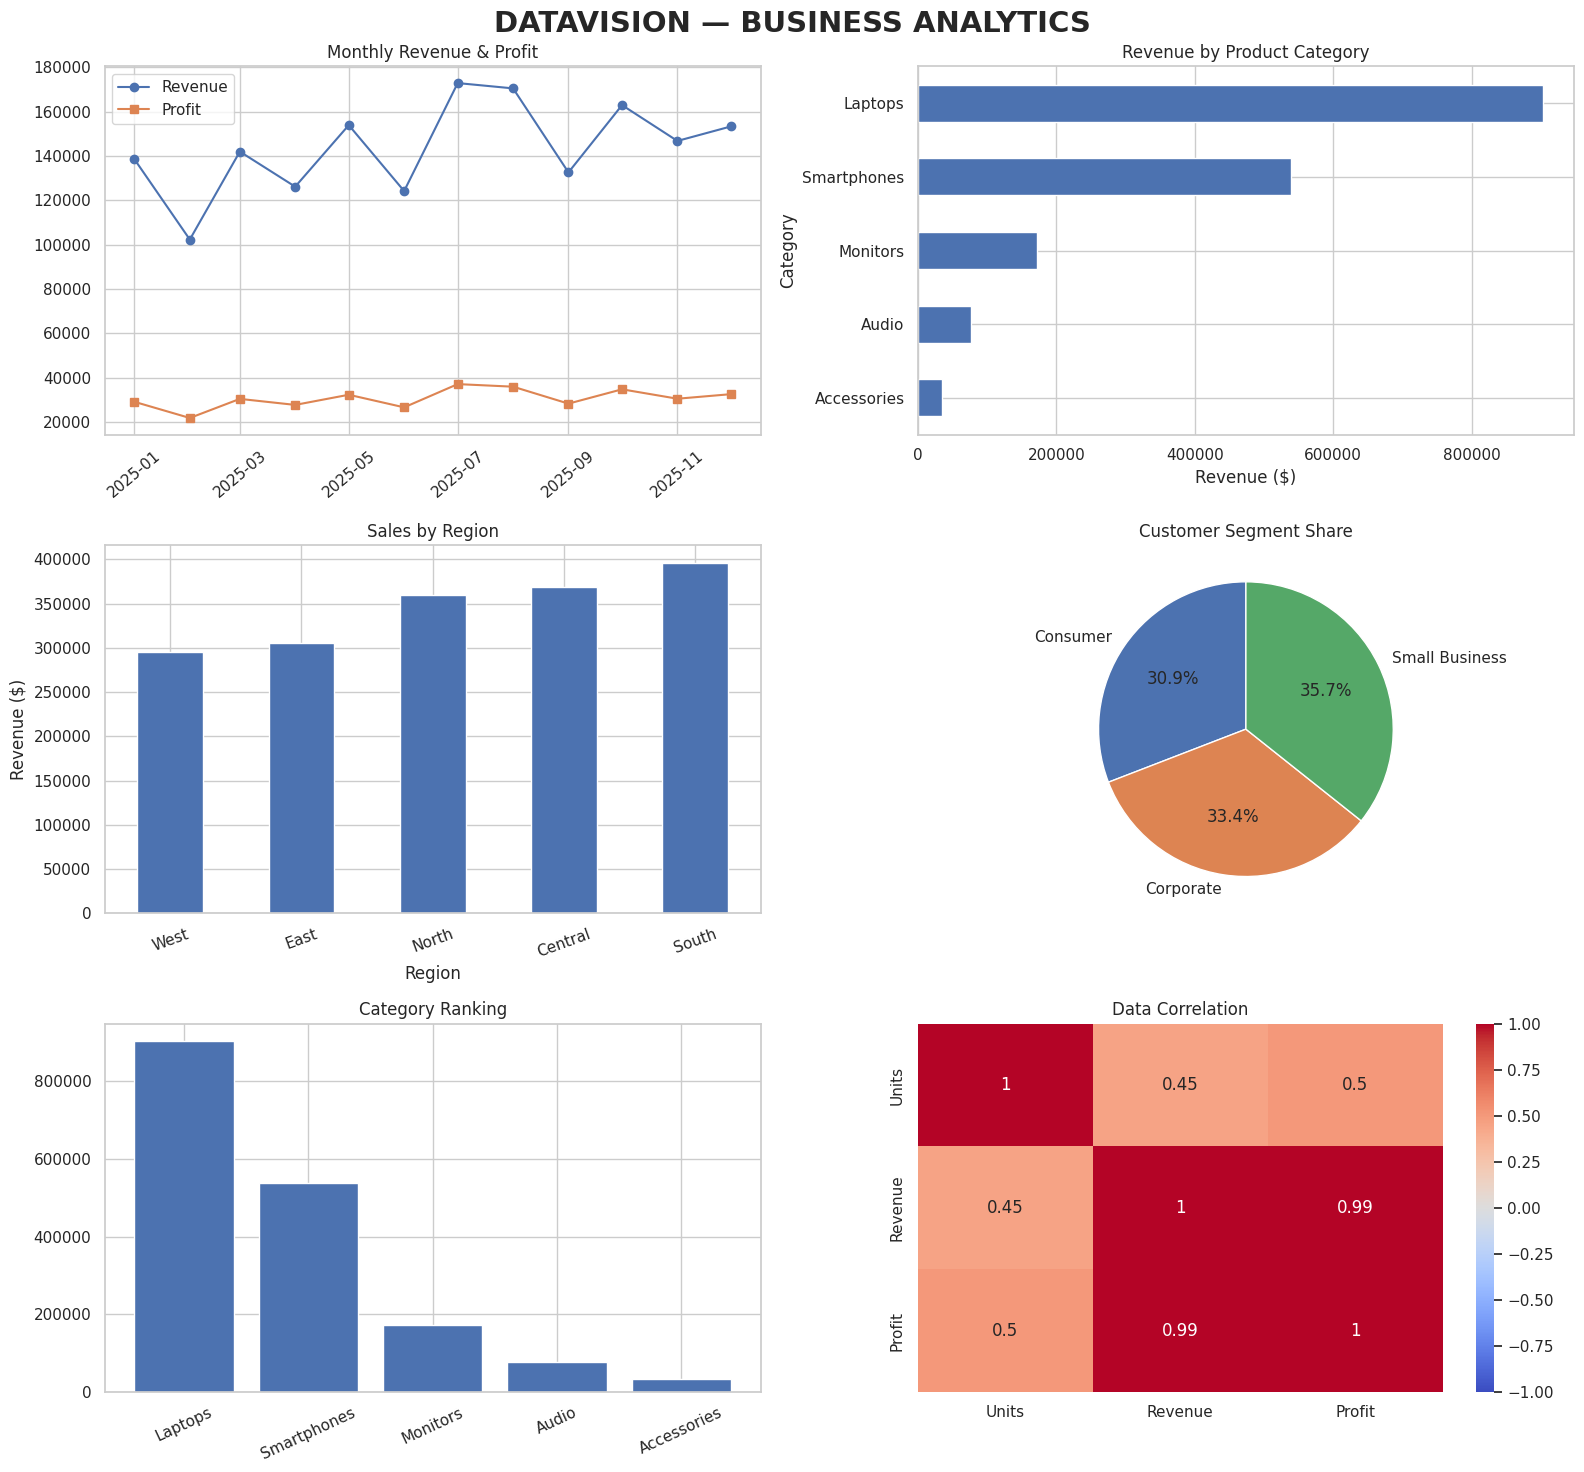

BUSINESS REPORT
-----------------------------------
Total Revenue: $1,725,989.45
Total Profit: $367,857.85
Total Orders: 1,200
Best Category: Laptops
Best Region: South
Profit Margin: 21.3%

TOP 5 SALES RECORDS
      Date Category  Region     Revenue      Profit
2025-10-02  Laptops Central 6132.367650 1165.149854
2025-11-10  Laptops   North 6114.134067 1161.685473
2025-06-30  Laptops   North 6023.634456 1144.490547
2025-06-24  Laptops   North 5983.545086 1136.873566
2025-08-10  Laptops   South 5961.569762 1132.698255


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generate sample business data
np.random.seed(42)
n = 1200

categories = [
    "Laptops", "Smartphones", "Accessories",
    "Monitors", "Audio"
]

base_prices = {
    "Laptops": 950,
    "Smartphones": 620,
    "Accessories": 45,
    "Monitors": 280,
    "Audio": 120
}

category = np.random.choice(
    categories, n,
    p=[0.23, 0.25, 0.20, 0.16, 0.16]
)

units = np.random.randint(1, 6, n)

price = np.array([
    base_prices[c] for c in category
]) * np.random.uniform(0.8, 1.3, n)

revenue = units * price

profit_rate = np.array([
    {"Laptops": 0.19,
     "Smartphones": 0.22,
     "Accessories": 0.36,
     "Monitors": 0.24,
     "Audio": 0.31}[c]
    for c in category
])

profit = revenue * profit_rate

dates = pd.to_datetime(
    np.random.choice(
        pd.date_range("2025-01-01", "2025-12-31"),
        n
    )
)

df = pd.DataFrame({
    "Date": dates,
    "Category": category,
    "Units": units,
    "Revenue": revenue,
    "Profit": profit,
    "Region": np.random.choice(
        ["North", "South", "East", "West", "Central"], n
    ),
    "Segment": np.random.choice(
        ["Consumer", "Corporate", "Small Business"], n
    )
})

df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

# Dashboard style
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(3, 2, figsize=(16, 15))
fig.suptitle(
    "DATAVISION — BUSINESS ANALYTICS",
    fontsize=21, fontweight="bold"
)

# 1. Monthly revenue and profit
monthly = df.groupby("Month")[["Revenue", "Profit"]].sum()

ax[0, 0].plot(
    monthly.index, monthly["Revenue"],
    marker="o", label="Revenue"
)
ax[0, 0].plot(
    monthly.index, monthly["Profit"],
    marker="s", label="Profit"
)
ax[0, 0].set_title("Monthly Revenue & Profit")
ax[0, 0].legend()
ax[0, 0].tick_params(axis="x", rotation=40)

# 2. Revenue by category
category_sales = df.groupby("Category")["Revenue"].sum()
category_sales.sort_values().plot(
    kind="barh", ax=ax[0, 1]
)
ax[0, 1].set_title("Revenue by Product Category")
ax[0, 1].set_xlabel("Revenue ($)")

# 3. Regional performance
region_sales = df.groupby("Region")["Revenue"].sum()
region_sales.sort_values().plot(
    kind="bar", ax=ax[1, 0]
)
ax[1, 0].set_title("Sales by Region")
ax[1, 0].set_ylabel("Revenue ($)")
ax[1, 0].tick_params(axis="x", rotation=20)

# 4. Customer segment distribution
segment_sales = df.groupby("Segment")["Revenue"].sum()
ax[1, 1].pie(
    segment_sales,
    labels=segment_sales.index,
    autopct="%1.1f%%",
    startangle=90
)
ax[1, 1].set_title("Customer Segment Share")

# 5. Top products categories
top_categories = category_sales.sort_values(ascending=False)
ax[2, 0].bar(
    top_categories.index, top_categories.values
)
ax[2, 0].set_title("Category Ranking")
ax[2, 0].tick_params(axis="x", rotation=25)

# 6. Correlation heatmap
sns.heatmap(
    df[["Units", "Revenue", "Profit"]].corr(),
    annot=True, cmap="coolwarm",
    vmin=-1, vmax=1, ax=ax[2, 1]
)
ax[2, 1].set_title("Data Correlation")

plt.tight_layout()
plt.show()

# Business insights
print("BUSINESS REPORT")
print("-" * 35)
print(f"Total Revenue: ${df['Revenue'].sum():,.2f}")
print(f"Total Profit: ${df['Profit'].sum():,.2f}")
print(f"Total Orders: {len(df):,}")
print(
    "Best Category:",
    category_sales.idxmax()
)
print(
    "Best Region:",
    region_sales.idxmax()
)
print(
    "Profit Margin:",
    f"{df['Profit'].sum() / df['Revenue'].sum():.1%}"
)

print("\nTOP 5 SALES RECORDS")
print(
    df.nlargest(5, "Revenue")[
        ["Date", "Category", "Region", "Revenue", "Profit"]
    ].to_string(index=False)
)
